
## Rol: Data Science Analyst  Yami| Temática: Seguridad Electrónica y Física

Cubre todo el flujo técnico requerido
1. **Carga y Limpieza (ETL)** de los datos extraídos (acotado entre 700 y 2.000 registros y máx. 10 variables).
2. **Análisis Exploratorio (EDA)** y gráficos clave.
3. **Score Ponderado de Costo-Beneficio** (Modelo de Decisión comercial).
4. **Entrenamiento de Modelo ML (Random Forest)**, Tabla Train vs CV, Matriz de Confusión y Gráfica de Top 5 Features.
5. **Exportación del modelo (`.pickle`)** y del dataset limpio para el Dashboard.

In [1]:
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### 2. Carga de Datos (o Generación de Dataset Simulado para Pruebas)
*(Solution Engineer) cuando este el CSV/Excel de Apify/Make, solo tengo que reemplazar el bloque de simulación por `df = pd.read_csv('tu_archivo.csv')`.*

In [2]:
### 2. Carga automática de los 4 CSVs reales de Apify
import glob

# Busca todos los .csv en Colab (ignorando el dataset limpio si ya existía)
archivos = [f for f in sorted(glob.glob('/content/*.csv')) if 'limpio' not in f]
print("Archivos encontrados:", len(archivos), archivos)

assert len(archivos) > 0, "❌ No hay CSVs en /content/. Subilos en la carpeta de la izquierda primero."

cols_apify = [
    'itemId', 'title', 'brand', 'domainId', 'searchQuery',
    'price', 'originalPrice', 'soldQuantity',
    'isOfficialStore', 'freeShipping', 'installments/interestFree',
    'rating', 'ratingCount'
]

dfs = []
for ruta in archivos:
    tmp = pd.read_csv(ruta)
    for c in cols_apify:
        if c not in tmp.columns:
            tmp[c] = np.nan
    dfs.append(tmp[cols_apify])

df = pd.concat(dfs, ignore_index=True)

df = df.rename(columns={
    'itemId': 'item_id',
    'title': 'titulo',
    'brand': 'marca',
    'price': 'precio',
    'originalPrice': 'precio_anterior',
    'soldQuantity': 'vendidos',
    'isOfficialStore': 'tienda_oficial',
    'freeShipping': 'envio_gratis',
    'installments/interestFree': 'cuotas_sin_interes',
    'ratingCount': 'cantidad_resenas'
})

print(f"Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head()

Archivos encontrados: 4 ['/content/dataset_mercadolibre-scraper_2026-11-18_02-43-10-919.csv', '/content/dataset_mercadolibre-scraper_Kit Alarma inteligentes Hogar.csv', '/content/dataset_mercadolibre-scraper_Kit de cámaras CCTV.csv', '/content/dataset_mercadolibre-scraper_cerraduras inteligentes .csv']
Dataset cargado: 1102 filas y 13 columnas.


,item_id,titulo,marca,domainId,searchQuery,precio,precio_anterior,vendidos,tienda_oficial,envio_gratis,cuotas_sin_interes,rating,cantidad_resenas
0,MLA1684428683,Kit 2 Camaras Seguridad Geotek 3mp Ip Wifi Ext...,Geotek,MLA-SURVEILLANCE_CAMERAS,camara de seguridad wifi,97499,149999.00,10000.0,True,True,False,4.7,10428.0
1,MLA2031663874,Camara Seguridad Geotek 3mp Ip Wifi Exterior F...,Geotek,MLA-SURVEILLANCE_CAMERAS,camara de seguridad wifi,47999,74999.00,10000.0,True,True,False,4.7,11033.0
2,MLA3939217420,Cámara Ptz Doble Lente 360 Visión Nocturna,ANSHICAT,MLA-SURVEILLANCE_CAMERAS,camara de seguridad wifi,67281,116306.81,0.0,False,True,False,0.0,0.0
3,MLA2629083924,Cámara Seguridad WiFi 355° HD 2MP Suono Alexa ...,Suono,MLA-SURVEILLANCE_CAMERAS,camara de seguridad wifi,32999,69999.00,1000.0,True,True,False,4.8,265.0
4,MLA2768249448,Cámara de Seguridad WiFi 360° – Visión Nocturn...,Genérica,MLA-SURVEILLANCE_CAMERAS,camara de seguridad wifi,24156,46286.10,10000.0,False,True,False,4.4,3604.0


### 3. ETL y Preprocesamiento (Limpieza de Datos)

In [3]:
### 3. ETL y Preprocesamiento (Limpieza de Datos)

# 1. Eliminar publicaciones duplicadas entre búsquedas
df = df.drop_duplicates(subset=['item_id']).copy()

# 2. Precios a número (sin borrar el punto decimal)
for col_precio in ['precio', 'precio_anterior']:
    df[col_precio] = pd.to_numeric(df[col_precio], errors='coerce')

# 3. Convertir "true"/"false" a 1/0
def a_binario(serie):
    return serie.astype(str).str.strip().str.lower().isin(['true', '1', '1.0']).astype(int)

df['cuotas_sin_interes'] = a_binario(df['cuotas_sin_interes'])
df['envio_gratis'] = a_binario(df['envio_gratis'])
df['tienda_oficial'] = a_binario(df['tienda_oficial'])

# 4. Crear 'categoria' desde domainId
mapa_categorias = {
    'MLA-SURVEILLANCE_CAMERAS': 'Cámara / Kit CCTV',
    'MLA-HOME_ALARMS_AND_SENSORS': 'Alarma Inteligente',
    'MLA-ELECTRIC_LOCKS': 'Cerradura Digital',
    'MLA-DOOR_AND_WINDOW_LOCKS': 'Cerradura Digital',
    'MLA-ELECTRIC_ENTRANCE_INTERCOMS': 'Portero Visor',
    'MLA-ELECTRONIC_ACCESSORIES_AND_REPLACEMENTS': 'Accesorios CCTV',
    'MLA-ALARM_REMOTE_CONTROLS': 'Accesorios Alarma',
    'MLA-GAS_DETECTORS': 'Alarma Inteligente'
}
df['categoria'] = df['domainId'].map(mapa_categorias)
df = df.dropna(subset=['categoria']).copy()

# 5. Limpiar y unificar nombres de marcas
genericas = {
    '', 'nan', 'none', ',', '! ! !', 'no', 'na', 'other', 'general',
    'generic', 'generica', 'genérica', 'generico', 'genérico', 'generel',
    'nobrand', 'neutral', 'full', 'kit', 'camara', 'cámaras',
    'cerradura electrónica inteligente', 'smart lock'
}
df['marca'] = df['marca'].fillna('Genérica').astype(str).str.strip()
df['marca'] = np.where(df['marca'].str.lower().isin(genericas), 'Genérica', df['marca'].str.title())

# 6. Detectar combos/kits desde el título
patron_combo = r'\b(?:combo|kit|pack|piezas|pzas|set)\b|\bx\s?\d+\b|\b\d+\s?x\b'
df['es_combo'] = df['titulo'].str.lower().str.contains(patron_combo, regex=True, na=False).astype(int)

# 7. Limpiar nulos en numéricas y rating
df['cantidad_resenas'] = pd.to_numeric(df['cantidad_resenas'], errors='coerce').fillna(0).astype(int)
df['vendidos'] = pd.to_numeric(df['vendidos'], errors='coerce').fillna(0).astype(int)
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

df['rating'] = df['rating'].fillna(df.groupby('marca')['rating'].transform('median'))
df['rating'] = df['rating'].fillna(df['rating'].median())

df['precio_anterior'] = df['precio_anterior'].fillna(df['precio'])
df['precio_anterior'] = np.maximum(df['precio_anterior'], df['precio'])

# 8. Filtrar precios absurdos o nulos
df = df.dropna(subset=['precio'])
df = df[(df['precio'] > 5000) & (df['precio'] < 2000000)].copy()

# 9. Porcentaje de descuento y métrica de negocio
df['descuento_pct'] = np.where(
    df['precio_anterior'] > df['precio'],
    np.round(((df['precio_anterior'] - df['precio']) / df['precio_anterior']) * 100, 2),
    0.0
)
df['precio_prom_categoria'] = np.round(df.groupby('categoria')['precio'].transform('mean'), 2)
df['distancia_precio_prom_pct'] = np.round(
    ((df['precio'] - df['precio_prom_categoria']) / df['precio_prom_categoria']) * 100, 2
)

print("Nulos restantes por columna:")
print(df[['titulo', 'marca', 'categoria', 'precio', 'rating', 'vendidos']].isnull().sum())
print(f"\nFilas finales tras limpieza: {len(df)}")

Nulos restantes por columna:
titulo       0
marca        0
categoria    0
precio       0
rating       0
vendidos     0
dtype: int64

Filas finales tras limpieza: 1077


### 4. Análisis Exploratorio de Datos (EDA)

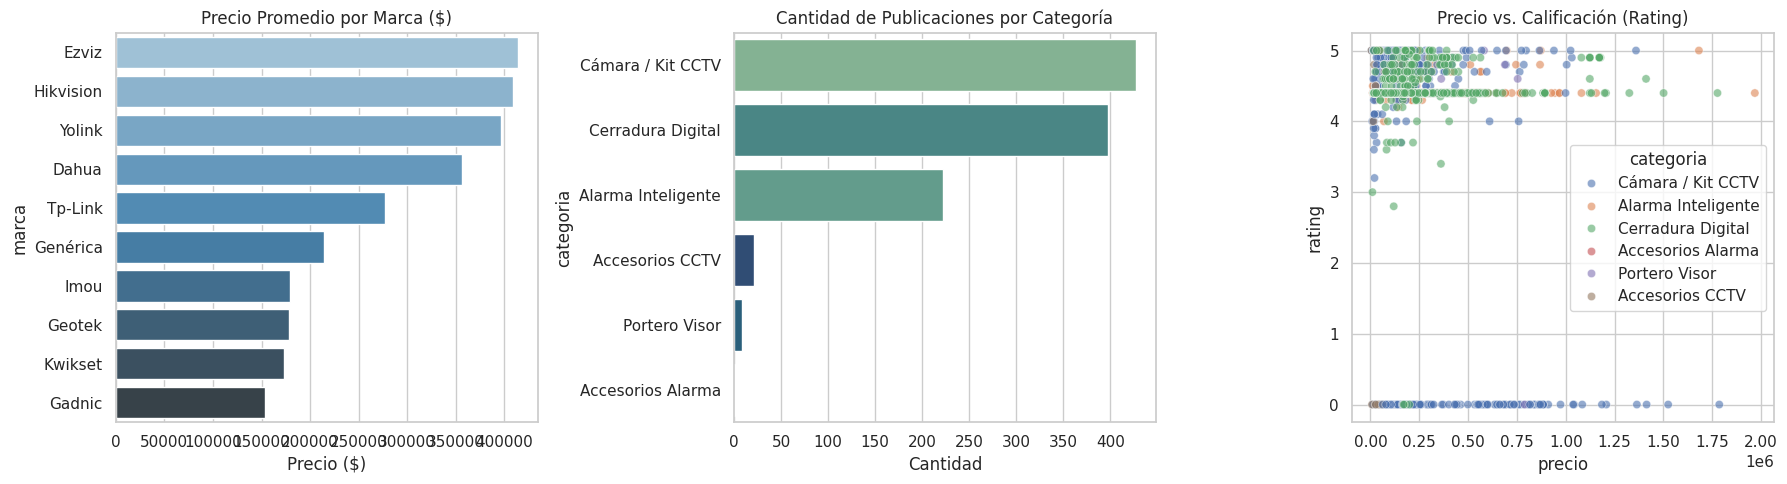

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Precio promedio por Marca
top10_marcas = df['marca'].value_counts().head(10).index
precio_marca = df[df['marca'].isin(top10_marcas)].groupby('marca')['precio'].mean().sort_values(ascending=False)
sns.barplot(x=precio_marca.values, y=precio_marca.index, hue=precio_marca.index, ax=axes[0], palette='Blues_d', legend=False)
axes[0].set_title('Precio Promedio por Marca ($)')
axes[0].set_xlabel('Precio ($)')

# Gráfico 2: Distribución de Categorías
sns.countplot(data=df, y='categoria', hue='categoria', order=df['categoria'].value_counts().index, ax=axes[1], palette='crest', legend=False)
axes[1].set_title('Cantidad de Publicaciones por Categoría')
axes[1].set_xlabel('Cantidad')

# Gráfico 3: Relación Precio vs Rating
sns.scatterplot(data=df, x='precio', y='rating', hue='categoria', alpha=0.6, ax=axes[2])
axes[2].set_title('Precio vs. Calificación (Rating)')

plt.tight_layout()
plt.show()

### 5. Modelo de Decisión: Score Ponderado de Costo-Beneficio (0 a 100)
Combinación
 Precio competitivo, Rating, Cantidad de Reseñas y Promociones (cuotas + envío gratis).

In [5]:
# Normalizamos el precio DENTRO de cada categoría (para no castigar a los Kits frente a Cámaras sueltas)
min_cat = df.groupby('categoria')['precio'].transform('min')
max_cat = df.groupby('categoria')['precio'].transform('max')
rango_cat = (max_cat - min_cat).replace(0, 1)

norm_precio = 1 - ((df['precio'] - min_cat) / rango_cat)
norm_rating = (df['rating'] - 1) / 4.0

rango_resenas = (df['cantidad_resenas'].max() - df['cantidad_resenas'].min()) or 1
norm_resenas = (df['cantidad_resenas'] - df['cantidad_resenas'].min()) / rango_resenas

norm_promos = (df['cuotas_sin_interes'] + df['envio_gratis']) / 2.0

df['score_costo_beneficio'] = np.round(
    (0.35 * norm_precio + 0.30 * norm_rating + 0.20 * norm_resenas + 0.15 * norm_promos) * 100, 2
)
df['es_competitivo'] = (df['score_costo_beneficio'] >= 65).astype(int)

display(df[['titulo', 'marca', 'categoria', 'precio', 'distancia_precio_prom_pct', 'score_costo_beneficio']].sort_values(by='score_costo_beneficio', ascending=False).head())

,titulo,marca,categoria,precio,distancia_precio_prom_pct,score_costo_beneficio
36,TP-Link Tapo C200 Cámara de Seguridad WiFi Int...,Tp-Link,Cámara / Kit CCTV,47943,-81.37,90.92
18,Camara Vigilancia TP-Link Tapo C500 WIFI IP pa...,Tp-Link,Cámara / Kit CCTV,59999,-76.69,83.24
90,Cámara De Seguridad Wifi Gadnic SX9 Ip 1080p V...,Gadnic,Cámara / Kit CCTV,44999,-82.52,82.96
450,Caja De Conexión Cctv X-28 + Accesorios - 100%...,X-28,Cámara / Kit CCTV,47220,-81.66,79.18
348,Camara Seguridad Ezviz Motorizada H6c Pro 2mp ...,Ezviz,Cámara / Kit CCTV,85306,-66.86,78.43


### 6. Entrenamiento del Modelo ML, Métricas y Exportación (`.pickle`)
Matriz de confusión, Tabla Train vs CV, Gráfica de Top 5 Features y exportación `.pickle`.

Balance vende_mucho:
 vende_mucho
0    0.724
1    0.276
Name: proportion, dtype: float64


,Métrica,Valor
0,Accuracy Train,0.9396
1,Accuracy CV (Media 5-Folds),0.9176
2,Diferencia Train - CV (Overfitting si > 0.1),0.0220
3,Accuracy Test,0.9167
4,Precision Test,0.9565
5,Recall Test,0.7333
6,F1-Score Test,0.8302



Reporte de Clasificación (Test):
              precision    recall  f1-score   support

           0       0.91      0.99      0.94       156
           1       0.96      0.73      0.83        60

    accuracy                           0.92       216
   macro avg       0.93      0.86      0.89       216
weighted avg       0.92      0.92      0.91       216



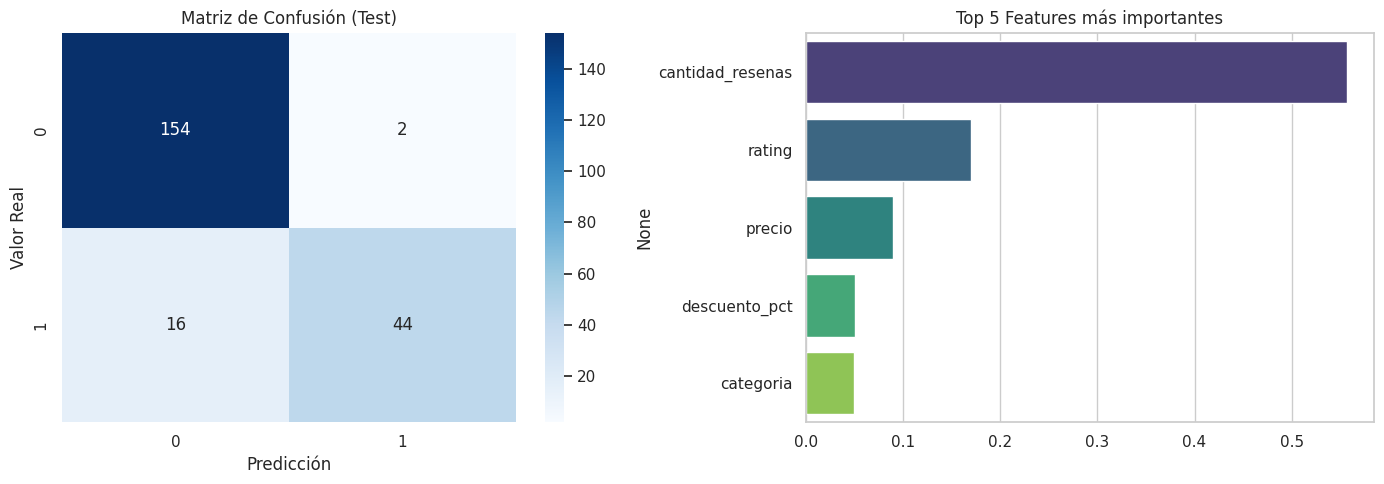


¡Listo! 'modelo_seguridad_capstone.pickle' y 'dataset_seguridad_limpio.csv' generados con éxito.


In [6]:
# 1. Definir Target REAL sin leakage: 'vende_mucho' (1 si vende >= mediana de su categoría)
mediana_positiva_cat = df[df['vendidos'] > 0].groupby('categoria')['vendidos'].median()
df['umbral_cat'] = df['categoria'].map(mediana_positiva_cat).fillna(25)
df['vende_mucho'] = (df['vendidos'] >= df['umbral_cat']).astype(int)
print("Balance vende_mucho:\n", df['vende_mucho'].value_counts(normalize=True).round(3))

# 2. Definir variables predictoras (SIN 'vendidos', SIN 'score_costo_beneficio', SIN 'es_competitivo')
cat_cols = ['marca', 'categoria']
num_cols = [
    'precio', 'descuento_pct', 'cuotas_sin_interes',
    'envio_gratis', 'es_combo', 'tienda_oficial',
    'rating', 'cantidad_resenas'
]
features = cat_cols + num_cols

X = df[features]
y = df['vende_mucho']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Pipeline con OrdinalEncoder seguro (si entra una marca/categoría nueva en producción, le pone -1 y NO se rompe)
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)
    ],
    remainder='passthrough'
)

pipeline = Pipeline([
    ('prep', preprocesador),
    ('modelo', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
])

pipeline.fit(X_train, y_train)

# 4. Predicciones y Métricas (Accuracy, Train vs CV, Precision, Recall, F1)
y_pred_train = pipeline.predict(X_train)
y_pred_test = pipeline.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')
test_acc = accuracy_score(y_test, y_pred_test)
test_prec = precision_score(y_test, y_pred_test, zero_division=0)
test_rec = recall_score(y_test, y_pred_test, zero_division=0)
test_f1 = f1_score(y_test, y_pred_test, zero_division=0)
diff_overfitting = round(train_acc - cv_scores.mean(), 4)

tabla_metricas = pd.DataFrame({
    'Métrica': [
        'Accuracy Train',
        'Accuracy CV (Media 5-Folds)',
        'Diferencia Train - CV (Overfitting si > 0.1)',
        'Accuracy Test',
        'Precision Test',
        'Recall Test',
        'F1-Score Test'
    ],
    'Valor': [
        round(train_acc, 4),
        round(cv_scores.mean(), 4),
        diff_overfitting,
        round(test_acc, 4),
        round(test_prec, 4),
        round(test_rec, 4),
        round(test_f1, 4)
    ]
})
display(tabla_metricas)
print("\nReporte de Clasificación (Test):")
print(classification_report(y_test, y_pred_test))

# 5. Gráficos: Matriz de Confusión y Top 5 Features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión (Test)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor Real')

modelo_rf = pipeline.named_steps['modelo']
importancias = pd.Series(modelo_rf.feature_importances_, index=features).sort_values(ascending=False).head(5)
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index, ax=axes[1], palette='viridis', legend=False)
axes[1].set_title('Top 5 Features más importantes')

plt.tight_layout()
plt.show()

# 6. Exportar artefacto (.pickle) y CSV limpio para Helen y Ramiro
artefacto_modelo = {
    'pipeline': pipeline,
    'features': features,
    'cat_cols': cat_cols,
    'num_cols': num_cols
}
with open('modelo_seguridad_capstone.pickle', 'wb') as f:
    pickle.dump(artefacto_modelo, f)

df.to_csv('dataset_seguridad_limpio.csv', index=False)
print("\n¡Listo! 'modelo_seguridad_capstone.pickle' y 'dataset_seguridad_limpio.csv' generados con éxito.")

In [7]:
### 6.5. Progressive AutoML: Batch Iterator (5 familias) + Optimización de Hiperparámetros
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV

# Preprocesador A: para modelos lineales / distancia / redes neuronales (OneHot + StandardScaler)
prep_escalado = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

# Preprocesador B: para modelos de árboles (OrdinalEncoder sin escalar, como el pipeline final)
prep_arboles = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)
    ],
    remainder='passthrough'
)

# Batch Iterator: 5 familias de modelos sobre exactamente la misma partición
modelos_comparar = {
    'Logistic Regression (Clásico)': Pipeline([('prep', prep_escalado), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    'KNN (Clásico)': Pipeline([('prep', prep_escalado), ('clf', KNeighborsClassifier(n_neighbors=5))]),
    'SVM (Clásico)': Pipeline([('prep', prep_escalado), ('clf', SVC(kernel='rbf', random_state=42))]),
    'Random Forest (Ensemble)': Pipeline([('prep', prep_arboles), ('clf', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))]),
    'Gradient Boosting (Ensemble)': Pipeline([('prep', prep_arboles), ('clf', GradientBoostingClassifier(random_state=42))]),
    'MLP Neural Network (Red Neuronal)': Pipeline([('prep', prep_escalado), ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))])
}

resultados = []
for nombre, pipe in modelos_comparar.items():
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy').mean()
    pipe.fit(X_train, y_train)
    pred_t = pipe.predict(X_test)
    resultados.append({
        'Modelo': nombre,
        'CV Accuracy (5-Folds)': round(cv_acc, 4),
        'Test Accuracy': round(accuracy_score(y_test, pred_t), 4),
        'Test F1-Score': round(f1_score(y_test, pred_t, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, pred_t, zero_division=0), 4)
    })

tabla_batch = pd.DataFrame(resultados).sort_values(by='CV Accuracy (5-Folds)', ascending=False)
print("=== Comparación de Modelos (Batch Iterator) ===")
display(tabla_batch)

# Optimización de Hiperparámetros sobre el modelo elegido (Random Forest)
param_dist = {
    'modelo__n_estimators': [100, 150, 200, 300],
    'modelo__max_depth': [4, 6, 8, 10, None],
    'modelo__min_samples_split': [2, 5, 10],
    'modelo__min_samples_leaf': [1, 2, 4]
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=15,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
search.fit(X_train, y_train)

best_test_acc = accuracy_score(y_test, search.predict(X_test))
print("\n=== Optimización de Hiperparámetros (RandomizedSearchCV) ===")
print(f"Baseline Random Forest -> CV Accuracy: {cv_scores.mean():.4f} | Test Accuracy: {test_acc:.4f}")
print(f"Optimizado Random Forest -> CV Accuracy: {search.best_score_:.4f} | Test Accuracy: {best_test_acc:.4f}")
print("Mejores parámetros encontrados:", search.best_params_)

=== Comparación de Modelos (Batch Iterator) ===


,Modelo,CV Accuracy (5-Folds),Test Accuracy,Test F1-Score,Test Recall
3,Random Forest (Ensemble),0.9176,0.9167,0.8302,0.7333
4,Gradient Boosting (Ensemble),0.9106,0.9167,0.8302,0.7333
5,MLP Neural Network (Red Neuronal),0.8746,0.8472,0.6972,0.6333
0,Logistic Regression (Clásico),0.8304,0.8426,0.6909,0.6333
1,KNN (Clásico),0.8304,0.8241,0.6346,0.5500
2,SVM (Clásico),0.8037,0.8102,0.6019,0.5167



=== Optimización de Hiperparámetros (RandomizedSearchCV) ===
Baseline Random Forest -> CV Accuracy: 0.9176 | Test Accuracy: 0.9167
Optimizado Random Forest -> CV Accuracy: 0.9187 | Test Accuracy: 0.9074
Mejores parámetros encontrados: {'modelo__n_estimators': 300, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 2, 'modelo__max_depth': 4}


Prueba de producción + Versiones para helen

In [8]:
# Test rápido: simulamos que en producción entra una marca desconocida
with open('modelo_seguridad_capstone.pickle', 'rb') as f:
    artefacto = pickle.load(f)

ejemplo_nuevo = pd.DataFrame([{
    'marca': 'MarcaNuevaDesconocida',
    'categoria': 'Cámara / Kit CCTV',
    'precio': 85000.0,
    'descuento_pct': 15.0,
    'cuotas_sin_interes': 1,
    'envio_gratis': 1,
    'es_combo': 0,
    'tienda_oficial': 1,
    'rating': 4.7,
    'cantidad_resenas': 120
}])

pred = artefacto['pipeline'].predict(ejemplo_nuevo[artefacto['features']])[0]
prob = artefacto['pipeline'].predict_proba(ejemplo_nuevo[artefacto['features']])[0][1]
print(f"Prueba con marca nueva OK -> Predicción vende_mucho: {pred} (Probabilidad: {prob:.2%})\n")

# Versiones para pasarle a Helen (para el requirements.txt del Actor de Apify)
print("=== VERSIONES PARA Helen ===")
print(f"Python: {sys.version.split()[0]}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print(f"scikit-learn=={sklearn.__version__}")

Prueba con marca nueva OK -> Predicción vende_mucho: 1 (Probabilidad: 90.25%)

=== VERSIONES PARA Helen ===
Python: 3.13.18
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
